# Estado del arte: los enfoques de calibración de Tasche comparados sobre S&P 2010 y 2011

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 05 y 07 de este tema (los enfoques y la función IRB)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar lo que dice la investigación sobre llevar una curva de PD a un período nuevo: el hallazgo de Tasche sobre el escalamiento, y las otras prácticas que lista;
- comparar nueve enfoques sobre los mismos dos años de pronóstico por la PD que pronostica cada uno frente a la PD observada, la prueba chi-cuadrado del perfil de incumplimiento implicado y el ponderador de riesgo IRB;
- decir qué comparación separa a los enfoques y cuál no, y por qué un año de 63 incumplimientos no puede ordenarlos a todos;
- decir qué hace y qué no hace el producto en cada práctica.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import capital_requirement

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos archivos versionados del caso C05, la calibración de una curva de PD sobre las calificaciones corporativas de S&P de Tasche (2013) (clase de licencia `derived-only`, así que solo se versionan tasas, perfiles y resultados, nunca conteos por grado; https://doi.org/10.21314/jcr.2013.169): `data/derived/C05/sp-2010.json` y `data/derived/C05/sp-2011.json`. Cada uno guarda el modelo de estimación de 2009, el perfil del año de pronóstico y su PD observada, la curva de cada uno de nueve enfoques (`approaches`), sus pruebas versionadas (`tests`) y el impacto en capital (`impact`). La celda siguiente los carga.

In [2]:
# Cargar los dos artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
years = {y: json.loads((C05 / f"sp-{y}.json").read_text(encoding="utf-8")) for y in (2010, 2011)}
ids = list(years[2010]["outputs"]["approaches"])
names = {"A1-idp": "perfil de incumplimiento invariante", "A2-iar": "razón de precisión invariante", "A3-spd": "PD escaladas",
         "A4-slr": "razón de verosimilitud escalada", "B1-ilr": "RV invariante, PD conocida", "C1-ipc": "curva de PD invariante (2009 sin cambios)",
         "C2-ls": "perfiles condicionales, mínimos cuadrados", "C3-chi2": "perfiles condicionales, mínimo chi-cuadrado", "C4-ilr": "RV invariante, perfil conocido"}
for y, doc in years.items():
    o = doc["outputs"]
    print(y, "| calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__, "| PD observada", round(o["pd1"], 6), "| incumplimientos", o["n_defaults"], "de", o["n_obligors"])
print("enfoques:", ids)

2010 | calculado con riskvalidation 0.4.3 | instalado 0.9.0 | PD observada 0.011409 | incumplimientos 63 de 5522
2011 | calculado con riskvalidation 0.4.3 | instalado 0.9.0 | PD observada 0.007525 | incumplimientos 44 de 5847
enfoques: ['A1-idp', 'A2-iar', 'A3-spd', 'A4-slr', 'B1-ilr', 'C1-ipc', 'C2-ls', 'C3-chi2', 'C4-ilr']


## Método

**La comparación.** Los nueve enfoques de Tasche (cuaderno 05) se ordenan por lo que se sabe al comenzar el año nuevo: caso 1 (el perfil y la PD: A1 a A4), caso 2 (solo la PD: B1) y caso 3 (solo el perfil: C1 a C4). Tres lecturas los comparan en los dos años de pronóstico:

1. **La PD que pronostica cada uno frente a la PD observada.** Los enfoques de los casos 1 y 2 reciben la PD; los del caso 3 deben producirla, solo desde el perfil. La razón entre la PD pronosticada y la observada dice cuánto cuesta no conocerla.
2. **La prueba chi-cuadrado del perfil de incumplimiento implicado** (`pd.default_profile`): si los incumplimientos cayeron en los grados como lo implica la curva. Ve la forma, no el nivel.
3. **El ponderador de riesgo IRB medio** de la cartera del pronóstico bajo cada curva: lo que cuesta la elección en capital.

Un año tiene 63 incumplimientos en 2010 y 44 en 2011 sobre 17 grados, y la mayoría de los grados tiene cero o uno. No cabe esperar que las pruebas separen cada par. La celda siguiente imprime la PD pronosticada, la observada y su razón para los nueve enfoques en ambos años.

In [3]:
# La PD pronosticada de cada enfoque frente a la PD observada, ambos años
print(f"{'':10s}" + "".join(f"{y} pronóstico   {y} razón   " for y in years))
for aid in ids:
    cells = []
    for y, doc in years.items():
        o = doc["outputs"]
        forecast = o["approaches"][aid]["pd"]
        cells.append(f"{100 * forecast:12.3f}%{forecast / o['pd1']:12.2f}   ")
    print(f"{aid:10s}" + "".join(cells))
print("PD observada (%):", {y: round(100 * doc["outputs"]["pd1"], 3) for y, doc in years.items()})
for y, doc in years.items():
    o = doc["outputs"]
    case3 = [o["approaches"][a]["pd"] / o["pd1"] for a in ("C1-ipc", "C2-ls", "C3-chi2", "C4-ilr")]
    print(y, "| pronósticos del caso 3 como múltiplo de la PD observada, de menor a mayor:", round(min(case3), 2), "a", round(max(case3), 2))

          2010 pronóstico   2010 razón   2011 pronóstico   2011 razón   
A1-idp           1.141%        1.00          0.753%        1.00   
A2-iar           1.141%        1.00          0.753%        1.00   
A3-spd           1.141%        1.00          0.753%        1.00   
A4-slr           1.141%        1.00          0.753%        1.00   
B1-ilr           1.546%        1.36          0.868%        1.15   
C1-ipc           4.318%        3.78          3.751%        4.99   
C2-ls            4.799%        4.21          3.499%        4.65   
C3-chi2          5.347%        4.69          2.834%        3.77   
C4-ilr           5.377%        4.71          2.794%        3.71   
PD observada (%): {2010: 1.141, 2011: 0.753}
2010 | pronósticos del caso 3 como múltiplo de la PD observada, de menor a mayor: 3.78 a 4.71
2011 | pronósticos del caso 3 como múltiplo de la PD observada, de menor a mayor: 3.71 a 4.99


Los casos 1 y 2 reciben la PD, así que su pronóstico la iguala por construcción (el caso 2 da la PD bajo el perfil observado, cuaderno 05, que difiere). El caso 3 debe inferir la PD y se equivoca mucho en ambos años, de 3,7 a 5,0 veces de más: parte de la PD de 2009 de 3,99% y el perfil solo no dice que el año fue más tranquilo. Ahora la prueba del perfil de incumplimiento implicado.

In [4]:
# El valor p chi-cuadrado y la luz versionados del perfil de incumplimiento implicado, por enfoque y año, y el orden del caso 1
tests = {y: {t["model_id"]: t for t in doc["tests"] if t["test_id"] == "pd.default_profile"} for y, doc in years.items()}
print(f"{'':10s}" + "".join(f"{'p ' + str(y):>10s}{'luz':>8s}" for y in years))
for aid in ids:
    print(f"{aid:10s}" + "".join(f"{tests[y][aid]['p_value']:10.4f}{si_no(tests[y][aid]['light']):>8s}" for y in years))
case1 = ids[:4]
for y in years:
    ranked = sorted(case1, key=lambda a: -tests[y][a]["p_value"])
    print(y, "| caso 1 por valor p, de más a menos consistente con el perfil observado:", " > ".join(ranked))
print("enfoques en ámbar o rojo:", {y: [a for a in ids if tests[y][a]["light"] != "green"] for y in years})
print("error estándar Monte Carlo de los valores p, el mayor:", round(max(t["extras"]["mc_standard_error"] for y in years for t in tests[y].values()), 5))

              p 2010     luz    p 2011     luz
A1-idp        0.0458   ámbar    0.7817   verde
A2-iar        0.0791   verde    0.8910   verde
A3-spd        0.0425   ámbar    0.3696   verde
A4-slr        0.1115   verde    0.8199   verde
B1-ilr        0.1011   verde    0.8076   verde
C1-ipc        0.0425   ámbar    0.3696   verde
C2-ls         0.0335   ámbar    0.4215   verde
C3-chi2       0.0293   ámbar    0.5095   verde
C4-ilr        0.0291   ámbar    0.5153   verde
2010 | caso 1 por valor p, de más a menos consistente con el perfil observado: A4-slr > A2-iar > A1-idp > A3-spd
2011 | caso 1 por valor p, de más a menos consistente con el perfil observado: A2-iar > A4-slr > A1-idp > A3-spd
enfoques en ámbar o rojo: {2010: ['A1-idp', 'A3-spd', 'C1-ipc', 'C2-ls', 'C3-chi2', 'C4-ilr'], 2011: []}
error estándar Monte Carlo de los valores p, el mayor: 0.00158


Las pruebas separan más los años que los enfoques: en 2011 los nueve quedan en verde (p desde 0,37), y en 2010 seis quedan en ámbar: el perfil de incumplimiento invariante, las PD escaladas y los cuatro enfoques del caso 3. La razón de verosimilitud escalada, la razón de precisión invariante y el caso 2 quedan en verde. En ambos años las PD escaladas quedan últimas del caso 1. Con 44 o 63 incumplimientos, la mayoría en los últimos grados, la prueba tiene poco que decir para distinguir a los enfoques del caso 1 más allá de eso; el orden se lee con eso en mente. Ahora el costo en capital.

In [5]:
# El ponderador IRB medio de la cartera del pronóstico bajo cada curva, desde el impacto versionado, y las dispersiones
irb = years[2010]["outputs"]["irb"]
print("supuestos IRB:", {k: v for k, v in irb.items() if k != "references"})
print(f"{'':10s}" + "".join(f"{'ponderador ' + str(y):>20s}" for y in years))
for aid in ids:
    print(f"{aid:10s}" + "".join(f"{years[y]['impact']['rw_' + aid]['value']:20.4f}" for y in years))
for y in years:
    imp = years[y]["impact"]
    print(y, "| dispersión de los cuatro enfoques del caso 1:", f"{100 * imp['rw_spread_case1']['value']:.1f}%", "| la curva de 2009 sin cambios frente a la razón de verosimilitud escalada:", f"{100 * imp['rw_stale_vs_slr']['value']:.1f}%")
o = years[2010]["outputs"]
floor_hits = {aid: int(sum(p < irb["pd_floor"] for p in o["approaches"][aid]["curve"])) for aid in ids}
print("grados de 17 cuya PD de 2010 queda bajo el piso de 0.05%, por enfoque:", floor_hits)

supuestos IRB: {'regime': 'basel3', 'asset_class': 'corporate', 'lgd': 0.45, 'maturity': 2.5, 'pd_floor': 0.0005}
               ponderador 2010     ponderador 2011
A1-idp                  0.6092              0.5156
A2-iar                  0.5732              0.4939
A3-spd                  0.5878              0.5347
A4-slr                  0.5504              0.5052
B1-ilr                  0.6158              0.5326
C1-ipc                  0.9068              0.9263
C2-ls                   0.9548              0.8892
C3-chi2                 0.9836              0.8318
C4-ilr                  0.9850              0.8280
2010 | dispersión de los cuatro enfoques del caso 1: 10.7% | la curva de 2009 sin cambios frente a la razón de verosimilitud escalada: 64.8%
2011 | dispersión de los cuatro enfoques del caso 1: 8.3% | la curva de 2009 sin cambios frente a la razón de verosimilitud escalada: 83.3%
grados de 17 cuya PD de 2010 queda bajo el piso de 0.05%, por enfoque: {'A1-idp': 6, 'A2-iar': 

## Estado del arte

### Lo que encontró la investigación, y lo que hace el producto

- **Escalar las PD es cuestionable.** Tasche (2013) muestra que multiplicar la vieja curva de PD por una constante, la práctica simple y extendida, es teóricamente cuestionable, y que la razón de precisión invariante por ajuste cuasi de momentos y la razón de verosimilitud escalada se comportan mucho mejor. *Producto:* los cuatro se calculan (cuaderno 05) y se comparan arriba; en estos dos años las PD escaladas tienen el menor valor p del caso 1 en ambos (0,043 en 2010, 0,370 en 2011).
- **Llevar la curva vieja sin cambios.** La curva de PD invariante es lo que hace un banco cuando mantiene la calibración del año pasado. *Producto:* se calcula como C1 y se muestra su precio: una PD pronosticada varias veces la observada y el mayor ponderador de riesgo.
- **Otros peldaños.** La investigación lista la recalibración del intercepto, el escalamiento de Platt y la regresión isotónica como formas de calibrar los puntajes de un modelo a PD, y los a priori bayesianos para carteras de bajo incumplimiento. *Producto:* estos trabajan sobre puntajes, no sobre un perfil de calificación, y quedan fuera de los enfoques comparados aquí; los intervalos de Jeffreys del cuaderno 02 son la posterior de un a priori Beta, y no se ajusta ningún otro a priori.
- **La comparación es un resultado de un año.** Dos años de pronóstico son dos muestras; las pruebas versionadas dicen qué enfoque es consistente con los incumplimientos del año, no cuál es correcto en general. El producto declara el límite y no ordena los enfoques más allá de él.

La figura dibuja la PD pronosticada sobre la observada para cada enfoque en 2010, y los ponderadores de riesgo de ambos años.

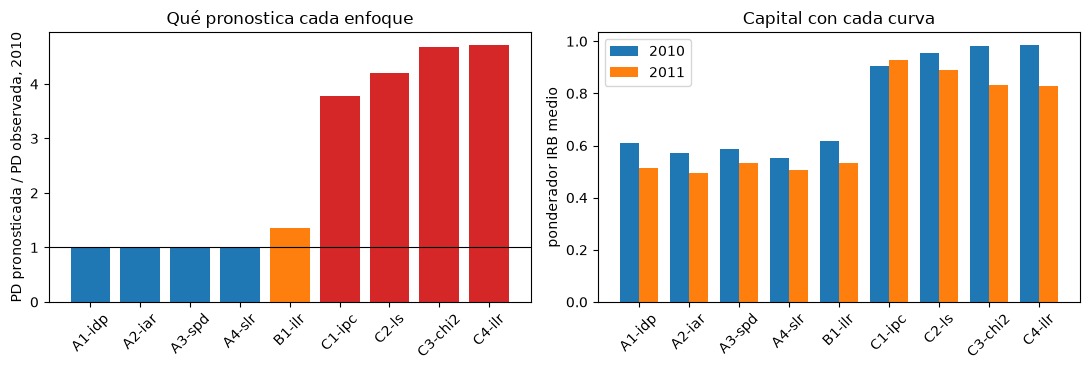

In [6]:
# Dibujar la razón pronóstico a observada de 2010 y los ponderadores de riesgo de ambos años por enfoque
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
o10 = years[2010]["outputs"]
left.bar(range(len(ids)), [o10["approaches"][a]["pd"] / o10["pd1"] for a in ids], color=["tab:blue"] * 4 + ["tab:orange"] + ["tab:red"] * 4)
left.axhline(1.0, color="black", linewidth=0.8)
left.set_xticks(range(len(ids)))
left.set_xticklabels(ids, rotation=45)
left.set_ylabel("PD pronosticada / PD observada, 2010")
left.set_title("Qué pronostica cada enfoque")
width = 0.38
for k, y in enumerate(years):
    right.bar(np.arange(len(ids)) + (k - 0.5) * width, [years[y]["impact"]["rw_" + a]["value"] for a in ids], width, label=str(y))
right.set_xticks(range(len(ids)))
right.set_xticklabels(ids, rotation=45)
right.set_ylabel("ponderador IRB medio")
right.set_title("Capital con cada curva")
right.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Pronóstico frente a observado.** Los enfoques de los casos 1 y 2 reciben la PD (el caso 2 da 1,55% bajo el perfil observado de 2010, 1,36 veces el 1,14% observado, y 0,87% en 2011, 1,15 veces 0,75%). Los cuatro enfoques del caso 3, que deben inferirla, pronostican de 3,78 a 4,71 veces la PD observada en 2010 y de 3,71 a 4,99 veces en 2011.
- **La prueba del perfil de incumplimiento implicado.** En 2011 los nueve enfoques quedan en verde (p de 0,37 a 0,89). En 2010 seis quedan en ámbar (p entre 0,029 y 0,046: el perfil de incumplimiento invariante 0,046, las PD escaladas 0,043, la curva de PD invariante 0,043 y los otros tres enfoques del caso 3 de 0,029 a 0,034), y la razón de verosimilitud escalada (0,112), el caso 2 (0,101) y la razón de precisión invariante (0,079) quedan en verde. Dentro del caso 1 el orden es razón de verosimilitud escalada, razón de precisión invariante, perfil de incumplimiento invariante, PD escaladas en 2010 y razón de precisión, razón de verosimilitud, perfil de incumplimiento, PD escaladas en 2011: las PD escaladas quedan últimas en ambos. El error Monte Carlo de cualquier valor p es a lo más 0,0016.
- **Capital.** En 2010 el ponderador de riesgo medio es 55,0% (razón de verosimilitud escalada), 57,3% (razón de precisión), 58,8% (PD escaladas), 60,9% (perfil de incumplimiento) y 61,6% (caso 2), frente a 90,7% a 98,5% para el caso 3; en 2011 49,4% a 53,5% frente a 82,8% a 92,6%. Los cuatro enfoques del caso 1 se dispersan 10,7% en 2010 y 8,3% en 2011; la curva de 2009 sin cambios pide 64,8% y 83,3% más que la razón de verosimilitud escalada. El piso de PD de 0,05% obliga en 6 o 7 de los 17 grados con las curvas de los casos 1 y 2, así que los grados buenos pesan lo mismo sea cual sea el enfoque.
- **Lo que la comparación no puede decir.** Dos años de pronóstico son dos muestras. Las pruebas muestran que las PD escaladas y los enfoques del caso 3 ajustan peor los incumplimientos de 2010 que la razón de verosimilitud escalada y la razón de precisión invariante, y que nada separa a nada en 2011. No ordenan los enfoques en general.

Lo que este cuaderno no muestra: cómo se construyen las curvas (cuaderno 05) ni cómo la función IRB convierte una PD en capital (cuaderno 07).

## Resumen

- Los enfoques que conocen el perfil y la PD del año ajustan mejor los incumplimientos de 2010 que escalar las PD o mantener la curva vieja; en 2011 nada los separa.
- No conocer la PD (caso 3) pronostica de 3,7 a 5,0 veces la PD observada y cuesta de 65% a 83% más capital que la razón de verosimilitud escalada.
- La prueba chi-cuadrado ve la forma de una curva con pocos incumplimientos y no ordena los enfoques en general; el producto lo dice.
- Las prácticas de la investigación sobre puntajes (Platt, isotónica, intercepto) y los a priori bayesianos no se corren aquí sobre un perfil de calificación.

**Qué probar después.** Lee las metas de 2009 del cuaderno 05 y pregunta qué enfoque se habría elegido de antemano; luego lee el cuaderno 10.

## Referencias

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, Tablas 6 a 8 y secciones 4.2 a 4.4. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de activos ponderados por riesgo (LGD, vencimiento y piso de PD). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Platt, J. (1999), Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods, en Advances in Large Margin Classifiers, MIT Press, para el peldaño que lista la investigación.